# Lesson 9: Neural networks for house prices

Compare linear regression, a Keras network, and a neural network implemented with NumPy on the same ParisHousing data split. Run from this folder with pandas, NumPy, Matplotlib, scikit-learn, and TensorFlow installed.

**Data:** [Paris Housing Price Prediction](https://www.kaggle.com/datasets/mssmartypants/paris-housing-price-prediction). Place `ParisHousing.csv` in this lesson folder.

In [1]:
import os
os.environ["TF_NUM_INTRAOP_THREADS"] = "1"
os.environ["TF_NUM_INTEROP_THREADS"] = "1"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression

np.random.seed(42)
df = pd.read_csv("ParisHousing.csv")
df.head()

,squareMeters,numberOfRooms,hasYard,hasPool,floors,cityCode,cityPartRange,numPrevOwners,made,isNewBuilt,hasStormProtector,basement,attic,garage,hasStorageRoom,hasGuestRoom,price
0,75523,3,0,1,63,9373,3,8,2005,0,1,4313,9005,956,0,7,7559081.5
1,80771,39,1,1,98,39381,8,6,2015,1,0,3653,2436,128,1,2,8085989.5
2,55712,58,0,1,19,34457,6,8,2021,0,0,2937,8852,135,1,9,5574642.1
3,32316,47,0,0,6,27939,10,4,2012,0,1,659,7141,359,0,3,3232561.2
4,70429,19,1,1,90,38045,3,7,1990,1,0,8435,2429,292,1,4,7055052.0


## Split and scale

Keep a test split for final evaluation and a validation split for monitoring training. Fit feature and target scalers on the training set only.

In [2]:
X = df.drop(columns="price")
y = df[["price"]]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)
x_scaler = StandardScaler().fit(X_train)
y_scaler = StandardScaler().fit(y_train)
train_x, val_x, test_x = (x_scaler.transform(x) for x in (X_train, X_val, X_test))
train_y = y_scaler.transform(y_train)
val_y = y_scaler.transform(y_val)
print("Rows (train, validation, test):", len(X_train), len(X_val), len(X_test))

Rows (train, validation, test): 6400 1600 2000


## Baseline and Keras network

Train both models on the same rows. The Keras model uses standardized targets, then converts predictions back to the original price scale.

In [3]:
import tensorflow as tf
tf.keras.utils.set_random_seed(42)
baseline = LinearRegression().fit(train_x, y_train)
keras_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(train_x.shape[1],)),
    tf.keras.layers.Dense(32),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1),
])
keras_model.compile(optimizer="adam", loss="mse", metrics=["mae"])
history = keras_model.fit(train_x, train_y, validation_data=(val_x, val_y),
                          epochs=50, batch_size=64, verbose=0)

W0000 00:00:1793917537.066819  411370 cpu_utils.cc:145] Failed to get CPU frequency: 0 Hz
W0000 00:00:1793917537.078717  411370 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: goo.gle/debugonly    type: "CPU" model: "0" num_cores: 8 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.5.0" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


W0000 00:00:1793917538.834817  411370 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: goo.gle/debugonly    type: "CPU" model: "0" num_cores: 8 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.5.0" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


W0000 00:00:1793917540.190184  411370 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: goo.gle/debugonly    type: "CPU" model: "0" num_cores: 8 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.5.0" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


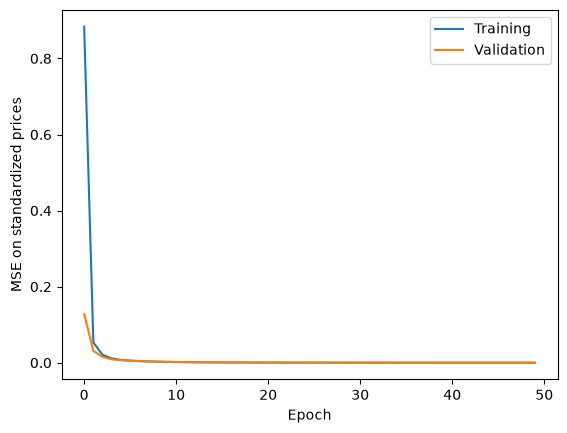

In [4]:
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("MSE on standardized prices")
plt.legend()
plt.show()

## NumPy network

The original implementation uses a linear first layer, a ReLU hidden layer, and Adam updates. It trains on the same standardized data.

In [5]:
import numpy as np

class NeuralNetwork:
    def __init__(self, layers, learning_rate=0.01, epochs=5000):
        self.layers = layers
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.weights = [np.random.randn(layers[i], layers[i+1]) * np.sqrt(2/layers[i])
                        for i in range(len(layers)-1)]
        self.biases = [np.zeros((1, layers[i+1])) for i in range(len(layers)-1)]

        self.m_w = [np.zeros_like(W) for W in self.weights]
        self.v_w = [np.zeros_like(W) for W in self.weights]
        self.m_b = [np.zeros_like(b) for b in self.biases]
        self.v_b = [np.zeros_like(b) for b in self.biases]
        self.beta1 = 0.9
        self.beta2 = 0.999
        self.eps = 1e-8

    @staticmethod
    def relu(x):
        return np.maximum(0, x)

    @staticmethod
    def relu_derivative(x):
        return (x > 0).astype(float)

    def learn(self, X_train, y_train):
        for epoch in range(self.epochs):
            activations = [X_train]
            z_values = []

            for i, (W, b) in enumerate(zip(self.weights, self.biases)):
                z = np.dot(activations[-1], W) + b
                z_values.append(z)
                if i == 0:
                    activations.append(z)
                elif i < len(self.weights) - 1:
                    activations.append(self.relu(z))
                else:
                    activations.append(z)

            m = X_train.shape[0]
            error = activations[-1] - y_train
            mse = np.mean(error**2)
            mae = np.mean(np.abs(error))

            if epoch % 100 == 0 or epoch == self.epochs - 1:
                print(f"Эпоха {epoch}: MSE = {mse:.4f}, MAE = {mae:.4f}")

            delta = error
            grads_w = []
            grads_b = []
            for i in reversed(range(len(self.weights))):
                grad_w = np.dot(activations[i].T, delta) / m
                grad_b = np.mean(delta, axis=0, keepdims=True)
                grads_w.insert(0, grad_w)
                grads_b.insert(0, grad_b)

                if i > 0:
                    delta = np.dot(delta, self.weights[i].T)
                    if i > 1:
                        delta *= self.relu_derivative(z_values[i-1])

            for i in range(len(self.weights)):
                self.m_w[i] = self.beta1 * self.m_w[i] + (1 - self.beta1) * grads_w[i]
                self.v_w[i] = self.beta2 * self.v_w[i] + (1 - self.beta2) * (grads_w[i] ** 2)
                m_hat_w = self.m_w[i] / (1 - self.beta1 ** (epoch + 1))
                v_hat_w = self.v_w[i] / (1 - self.beta2 ** (epoch + 1))
                self.weights[i] -= self.learning_rate * m_hat_w / (np.sqrt(v_hat_w) + self.eps)

                self.m_b[i] = self.beta1 * self.m_b[i] + (1 - self.beta1) * grads_b[i]
                self.v_b[i] = self.beta2 * self.v_b[i] + (1 - self.beta2) * (grads_b[i] ** 2)
                m_hat_b = self.m_b[i] / (1 - self.beta1 ** (epoch + 1))
                v_hat_b = self.v_b[i] / (1 - self.beta2 ** (epoch + 1))
                self.biases[i] -= self.learning_rate * m_hat_b / (np.sqrt(v_hat_b) + self.eps)

    def predict(self, X):
        activ = X
        for i, (W, b) in enumerate(zip(self.weights, self.biases)):
            z = np.dot(activ, W) + b
            if i == 0 or i == len(self.weights) - 1:
                activ = z
            else:
                activ = self.relu(z)
        return activ

    def evaluate(self, X, y):
        y_pred = self.predict(X)
        mae = np.mean(np.abs(y_pred - y))
        return mae


In [6]:
nn = NeuralNetwork(layers=[train_x.shape[1], 32, 16, 1], learning_rate=0.01, epochs=300)
nn.learn(train_x, train_y)

Эпоха 0: MSE = 2.5554, MAE = 1.2901
Эпоха 100: MSE = 0.0027, MAE = 0.0408


Эпоха 200: MSE = 0.0003, MAE = 0.0126
Эпоха 299: MSE = 0.0001, MAE = 0.0065


## Test-set comparison

MAE and RMSE are in the same units as the dataset’s price column. R² compares each model with a constant predictor based on the test-set mean.

In [7]:
predictions = {
    "Linear regression": baseline.predict(test_x).ravel(),
    "Keras": y_scaler.inverse_transform(keras_model.predict(test_x, verbose=0)).ravel(),
    "NumPy network": y_scaler.inverse_transform(nn.predict(test_x)).ravel(),
}
pd.DataFrame({
    name: {
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R²": r2_score(y_test, pred),
    }
    for name, pred in predictions.items()
}).T.round(6)

,MAE,RMSE,R²
Linear regression,1509.489264,1922.801981,1.000000
Keras,5394.548828,7561.937318,0.999993
NumPy network,19416.819959,28524.495626,0.999907
